In [1]:
%pip install kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [kagglehub]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

100%|██████████| 66.0M/66.0M [00:02<00:00, 25.1MB/s]

Extracting files...


Path to dataset files: /home/filonoa1/.cache/kagglehub/datasets/mlg-ulb/creditcardfraud/versions/3


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import os

In [5]:
df = pd.read_csv(os.path.join(path, "creditcard.csv"))


# Train Random Forest

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


X = df.drop(columns=["Time", "Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=2
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    average_precision_score, PrecisionRecallDisplay
)
import matplotlib.pyplot as plt

# training 
model = RandomForestClassifier(
    n_estimators=100,        # number of trees
    class_weight="balanced", # handle imbalanced classes
    random_state=42,
    n_jobs=-1               
)
model.fit(X_train_scaled, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [37]:
# predict
threshold = 0.5
y_proba = model.predict_proba(X_test_scaled)[:, 1]
# y_pred = model.predict(X_test_scaled)
y_pred = (y_proba >= threshold).astype(int)


              precision    recall  f1-score   support

   Non-fraud       1.00      1.00      1.00     56864
       Fraud       0.93      0.81      0.86        98

    accuracy                           1.00     56962
   macro avg       0.96      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962

Confusion matrix:
[[56858     6]
 [   19    79]]
PR-AUC: 0.8770435615996297


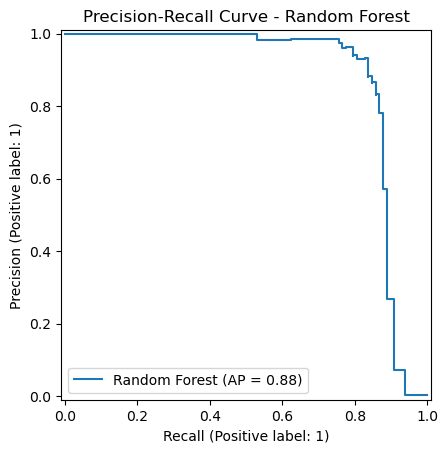

In [39]:
# evaluate
print(classification_report(y_test, y_pred, target_names=["Non-fraud", "Fraud"]))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("PR-AUC:", average_precision_score(y_test, y_proba))

PrecisionRecallDisplay.from_predictions(y_test, y_proba, name="Random Forest")
plt.title("Precision-Recall Curve - Random Forest")
plt.show()

In [ ]:
## Comments

PR-AUC = 0.8770
Rand forest catches 81% of fraud, but with significantly fewer false positives than log regr (6 compared to 1400)